# ML-experiment: förutsäga aktier som slår medianen

**Fråga:** Kan fem finansiella nyckeltal förutsäga om en akties avkastning *nästa år* blir högre än medianen för samma dataår?

**Upplägg**

| Steg | Data |
|---|---|
| Träning | 2014–2016 |
| Validering (modellval och inställningar) | 2017 |
| Slutligt test (körs en gång) | 2018 |

Två modeller (logistisk regression och Random Forest) jämförs mot en enkel baseline. Detta är ett experiment, inte ett investeringsråd.

## 1. Importer och inställningar

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, confusion_matrix, roc_auc_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42

FEATURES = [
    "ROE",
    "PE ratio",
    "Debt to Equity",
    "Net Profit Margin",
    "Gross Margin",
]

TRAIN_YEARS, VAL_YEAR, TEST_YEAR = [2014, 2015, 2016], 2017, 2018

## 2. Läs in data

Notebooken letar efter filen `2014_Financial_Data.csv` i aktuell mapp, i mappar ovanför och i undermappar (t.ex. `Data` eller `data`). 
Hittas den inte: skriv sökvägen till mappen med CSV-filerna i `MANUAL_DATA_DIR`.

In [2]:
# Fyll i vid behov, t.ex. MANUAL_DATA_DIR = r"C:/Users/ditt_namn/projekt/Data"
MANUAL_DATA_DIR = None

MARKER_FILE = "2014_Financial_Data.csv"


def find_data_dir():
    if MANUAL_DATA_DIR:
        return Path(MANUAL_DATA_DIR)

    start = Path.cwd().resolve()
    for base in [start, *start.parents][:5]:
        # 1) Direkt i mappen eller i Data/data
        for folder in [base, base / "Data", base / "data"]:
            if (folder / MARKER_FILE).exists():
                return folder
        # 2) Var som helst under mappen (begränsat djup)
        for hit in base.rglob(MARKER_FILE):
            if len(hit.relative_to(base).parts) <= 4:
                return hit.parent

    raise FileNotFoundError(
        f"Hittar inte {MARKER_FILE} från {start}. "
        "Sätt MANUAL_DATA_DIR till mappen där CSV-filerna ligger."
    )


DATA_DIR = find_data_dir()
print("Data-mapp:", DATA_DIR.resolve())
print("Filer:", sorted(p.name for p in DATA_DIR.glob("*_Financial_Data.csv")))

Data-mapp: C:\Users\Marcie\Financial2018\Data
Filer: ['2014_Financial_Data.csv', '2015_Financial_Data.csv', '2016_Financial_Data.csv', '2017_Financial_Data.csv', '2018_Financial_Data.csv']


## 3. Målvariabel och nyckeltal

För dataåret *Y* används kolumnen `Y+1 PRICE VAR [%]` (nästa års kursförändring). 
`target = 1` betyder att avkastningen är högre än **medianen för det året**, annars `0`. Medianen räknas per år så att marknadens allmänna upp- och nedgångar inte styr målet.

Rader utan känd avkastning tas bort. I nyckeltalen görs `inf` till saknade värden, som hanteras i modellens pipeline.

In [3]:
def load_year(year):
    df = pd.read_csv(DATA_DIR / f"{year}_Financial_Data.csv")

    return_col = f"{year + 1} PRICE VAR [%]"
    if return_col not in df.columns:
        raise KeyError(f"Kolumnen '{return_col}' saknas i filen för {year}.")
    missing = [c for c in FEATURES if c not in df.columns]
    if missing:
        raise KeyError(f"{year} saknar nyckeltal: {missing}")

    df["next_year_return"] = pd.to_numeric(df[return_col], errors="coerce")
    df = df.dropna(subset=["next_year_return"]).copy()

    median = df["next_year_return"].median()
    df["target"] = (df["next_year_return"] > median).astype(int)
    df["year"] = year

    df[FEATURES] = (
        df[FEATURES].apply(pd.to_numeric, errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
    )
    print(f"{year}: rader={len(df):>5}, median avkastning={median:7.2f} %, "
          f"andel target=1: {df['target'].mean():.3f}")
    return df[["year", *FEATURES, "next_year_return", "target"]]

data = {year: load_year(year) for year in TRAIN_YEARS + [VAL_YEAR, TEST_YEAR]}

C:\Users\Marcie\AppData\Local\Temp\ipykernel_4864\3934970823.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["next_year_return"] = pd.to_numeric(df[return_col], errors="coerce")


2014: rader= 3808, median avkastning=  -5.28 %, andel target=1: 0.500


C:\Users\Marcie\AppData\Local\Temp\ipykernel_4864\3934970823.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["next_year_return"] = pd.to_numeric(df[return_col], errors="coerce")


2015: rader= 4120, median avkastning=  17.28 %, andel target=1: 0.500


C:\Users\Marcie\AppData\Local\Temp\ipykernel_4864\3934970823.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["next_year_return"] = pd.to_numeric(df[return_col], errors="coerce")


2016: rader= 4797, median avkastning=  10.91 %, andel target=1: 0.500


C:\Users\Marcie\AppData\Local\Temp\ipykernel_4864\3934970823.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["next_year_return"] = pd.to_numeric(df[return_col], errors="coerce")


2017: rader= 4960, median avkastning= -13.34 %, andel target=1: 0.500
2018: rader= 4392, median avkastning=  17.64 %, andel target=1: 0.500


C:\Users\Marcie\AppData\Local\Temp\ipykernel_4864\3934970823.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["next_year_return"] = pd.to_numeric(df[return_col], errors="coerce")


## 4. Dela upp i träning, validering och test

Uppdelningen följer tiden: modellerna tränas på tidigare år och bedöms på senare år.

In [4]:
train_df = pd.concat([data[y] for y in TRAIN_YEARS], ignore_index=True)
val_df = data[VAL_YEAR]
test_df = data[TEST_YEAR]

X_train, y_train = train_df[FEATURES], train_df["target"]
X_val, y_val = val_df[FEATURES], val_df["target"]
X_test, y_test = test_df[FEATURES], test_df["target"]

print(f"Träning:    {X_train.shape}")
print(f"Validering: {X_val.shape}")
print(f"Test:       {X_test.shape}")

Träning:    (12725, 5)
Validering: (4960, 5)
Test:       (4392, 5)


## 5. Snabb datakontroll (endast träningsdata)

Saknade värden och extremvärden påverkar framför allt logistisk regression. Därför tittar vi på dem innan modellerna byggs.

In [5]:
overview = X_train.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).T
overview["saknas (%)"] = X_train.isna().mean() * 100
overview.round(2)

,count,mean,std,min,1%,25%,50%,75%,99%,max,saknas (%)
ROE,11482.0,1578.93,104566.25,-969.39,-4.15,-0.06,0.07,0.14,4.69,8255949.33,9.77
PE ratio,11562.0,43.73,1108.81,0.00,0.00,0.00,13.78,23.51,285.15,105828.71,9.14
Debt to Equity,11497.0,0.46,33.61,-2586.44,-12.86,0.00,0.42,1.06,12.66,2131.51,9.65
Net Profit Margin,11840.0,-7.50,164.25,-9704.67,-74.75,-0.02,0.04,0.13,0.86,97.40,6.95
Gross Margin,12106.0,0.48,1.10,-74.32,-0.17,0.25,0.46,0.80,1.00,31.00,4.86


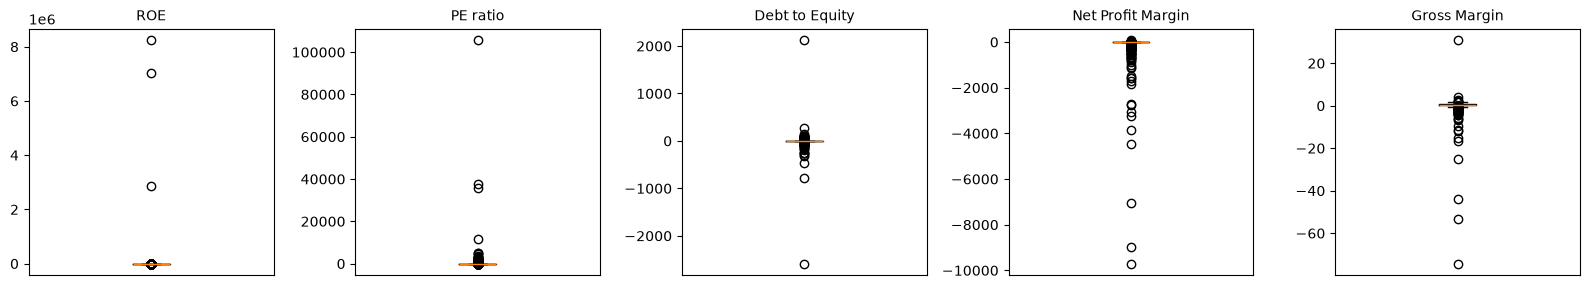

In [6]:
fig, axes = plt.subplots(1, len(FEATURES), figsize=(16, 3))
for ax, col in zip(axes, FEATURES):
    ax.boxplot(X_train[col].dropna(), showfliers=True)
    ax.set_title(col, fontsize=10)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

**Tolkning:** Om percentilerna visar mycket stora skillnader mellan medianen och maxvärdet finns tydliga extremvärden. 
Logistisk regression får därför ett extra steg som begränsar värden till träningsdatans 1:a och 99:e percentil (*winsorisering*). Gränserna lärs bara från träningsdata, så ingen information läcker från validering eller test. Random Forest påverkas inte av storleken på extremvärden och får inget sådant steg.

## 6. Modeller

In [7]:
class Winsorizer(BaseEstimator, TransformerMixin):
    """Begränsar varje kolumn till percentilgränser som lärs från träningsdata."""

    def __init__(self, lower=0.01, upper=0.99):
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.low_ = np.nanquantile(X, self.lower, axis=0)
        self.high_ = np.nanquantile(X, self.upper, axis=0)
        return self

    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.low_, self.high_)


def make_baseline():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyClassifier(strategy="most_frequent")),
    ])


def make_logreg(C=1.0):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("winsorizer", Winsorizer()),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(C=C, max_iter=2000, random_state=RANDOM_STATE)),
    ])


def make_rf(min_samples_leaf=5, max_depth=None):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            min_samples_leaf=min_samples_leaf,
            max_depth=max_depth,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ])


def evaluate(model, X, y):
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        "Accuracy": accuracy_score(y, pred),
        "Balanced accuracy": balanced_accuracy_score(y, pred),
        "ROC-AUC": roc_auc_score(y, proba),
    }

## 7. Välj inställningar på valideringsdata (2017)

Ett litet rutnät av inställningar testas för varje modell. Den inställning med högst **ROC-AUC på 2017** väljs. Testdata (2018) används inte i det här steget.

In [8]:
search_space = (
    [("Logistisk regression", {"C": C}, make_logreg(C)) for C in [0.01, 0.1, 1, 10]]
    + [
        ("Random Forest", {"min_samples_leaf": leaf, "max_depth": depth},
         make_rf(leaf, depth))
        for leaf in [5, 20, 50]
        for depth in [3, 5, None]
    ]
)

rows = []
for family, params, model in search_space:
    model.fit(X_train, y_train)
    rows.append({"Modell": family, "Inställning": str(params),
                 **evaluate(model, X_val, y_val), "_model": model})

tuning = pd.DataFrame(rows)
tuning.drop(columns="_model").sort_values(
    ["Modell", "ROC-AUC"], ascending=[True, False]
).round(4).reset_index(drop=True)

,Modell,Inställning,Accuracy,Balanced accuracy,ROC-AUC
0,Logistisk regression,{'C': 1},0.5893,0.5893,0.5907
1,Logistisk regression,{'C': 10},0.5893,0.5893,0.5907
2,Logistisk regression,{'C': 0.1},0.5891,0.5891,0.5907
3,Logistisk regression,{'C': 0.01},0.5891,0.5891,0.5905
4,Random Forest,"{'min_samples_leaf': 5, 'max_depth': 3}",0.5268,0.5268,0.5654
5,Random Forest,"{'min_samples_leaf': 20, 'max_depth': 3}",0.5274,0.5274,0.5652
6,Random Forest,"{'min_samples_leaf': 50, 'max_depth': 3}",0.5272,0.5272,0.5646
7,Random Forest,"{'min_samples_leaf': 5, 'max_depth': 5}",0.5147,0.5147,0.5574
8,Random Forest,"{'min_samples_leaf': 20, 'max_depth': 5}",0.5173,0.5173,0.5533
9,Random Forest,"{'min_samples_leaf': 50, 'max_depth': 5}",0.5179,0.5179,0.5487


## 8. Jämför modellerna på valideringsdata (2017)

In [9]:
best_logreg = tuning[tuning["Modell"] == "Logistisk regression"].nlargest(1, "ROC-AUC").iloc[0]
best_rf = tuning[tuning["Modell"] == "Random Forest"].nlargest(1, "ROC-AUC").iloc[0]

baseline = make_baseline().fit(X_train, y_train)

final_models = {
    "Baseline": baseline,
    "Logistisk regression": best_logreg["_model"],
    "Random Forest": best_rf["_model"],
}

print("Valda inställningar:")
print("  Logistisk regression:", best_logreg["Inställning"])
print("  Random Forest:       ", best_rf["Inställning"])

val_results = pd.DataFrame(
    {name: evaluate(model, X_val, y_val) for name, model in final_models.items()}
).T.sort_values("ROC-AUC", ascending=False)
val_results.round(4)

Valda inställningar:
  Logistisk regression: {'C': 1}
  Random Forest:        {'min_samples_leaf': 5, 'max_depth': 3}


,Accuracy,Balanced accuracy,ROC-AUC
Logistisk regression,0.5893,0.5893,0.5907
Random Forest,0.5268,0.5268,0.5654
Baseline,0.5000,0.5000,0.5000


### Hur säkra är skillnaderna?

Skillnaderna mellan modellerna är små, så vi uppskattar osäkerheten med bootstrap (omsampling av valideringsraderna) och visar ett 95 %-intervall för ROC-AUC. Om intervallet täcker 0,5 går det inte att skilja modellen från slumpen.

In [10]:
def bootstrap_auc(y_true, proba, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true)
    scores = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        scores.append(roc_auc_score(y_true[idx], proba[idx]))
    return np.percentile(scores, [2.5, 97.5])

ci_rows = []
for name in ["Logistisk regression", "Random Forest"]:
    proba = final_models[name].predict_proba(X_val)[:, 1]
    low, high = bootstrap_auc(y_val, proba)
    ci_rows.append({"Modell": name,
                    "ROC-AUC": roc_auc_score(y_val, proba),
                    "95 % intervall": f"[{low:.3f}, {high:.3f}]"})
pd.DataFrame(ci_rows).round(4)

,Modell,ROC-AUC,95 % intervall
0,Logistisk regression,0.5907,"[0.576, 0.607]"
1,Random Forest,0.5654,"[0.550, 0.582]"


## 9. Vilka nyckeltal bidrar mest?

Logistisk regression: koefficienter (efter winsorisering och standardisering, så de är jämförbara). 
Random Forest: viktighet baserad på hur mycket varje nyckeltal minskar osäkerheten i träden.

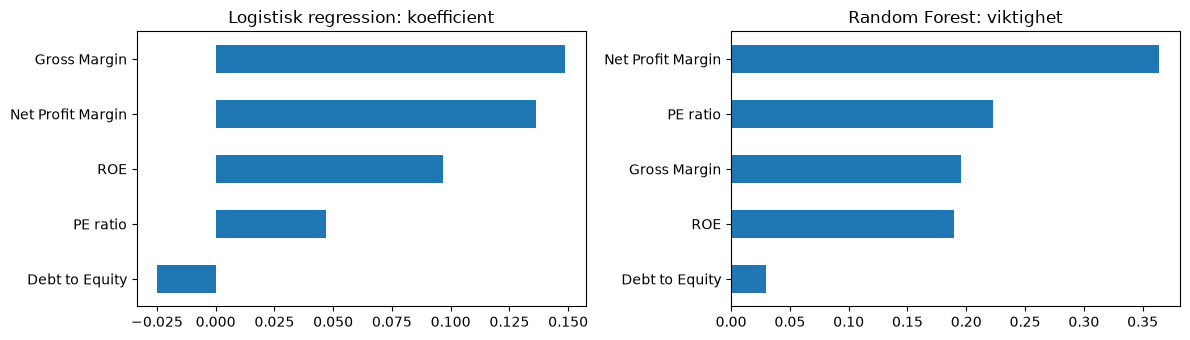

In [11]:
logreg_coef = pd.Series(
    final_models["Logistisk regression"].named_steps["model"].coef_[0], index=FEATURES
).sort_values()
rf_importance = pd.Series(
    final_models["Random Forest"].named_steps["model"].feature_importances_, index=FEATURES
).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
logreg_coef.plot(kind="barh", ax=axes[0], title="Logistisk regression: koefficient")
rf_importance.plot(kind="barh", ax=axes[1], title="Random Forest: viktighet")
plt.tight_layout()
plt.show()

## 10. Slutligt test på 2018

Modellvalet är gjort på 2017. Testet körs **en gång** som kontroll. Ändrar vi modell eller inställningar efter att ha sett 2018 blir året i praktiken ännu en valideringsmängd.

In [12]:
test_results = pd.DataFrame(
    {name: evaluate(model, X_test, y_test) for name, model in final_models.items()}
).T.sort_values("ROC-AUC", ascending=False)
test_results.round(4)

,Accuracy,Balanced accuracy,ROC-AUC
Random Forest,0.5849,0.5849,0.6081
Logistisk regression,0.5503,0.5503,0.5646
Baseline,0.5000,0.5000,0.5000


In [13]:
chosen_name = val_results.drop(index="Baseline")["ROC-AUC"].idxmax()
chosen_model = final_models[chosen_name]

test_pred = (chosen_model.predict_proba(X_test)[:, 1] >= 0.5).astype(int)
cm = pd.DataFrame(
    confusion_matrix(y_test, test_pred),
    index=["Verklig: under median", "Verklig: över median"],
    columns=["Förutsagd: under", "Förutsagd: över"],
)
print(f"Vald modell (högst ROC-AUC på 2017): {chosen_name}")
cm

Vald modell (högst ROC-AUC på 2017): Logistisk regression


,Förutsagd: under,Förutsagd: över
Verklig: under median,1207,989
Verklig: över median,986,1210


## 10b. Topp 10 % och botten 10 %

Aktierna rangordnas efter modellens sannolikhet för att slå medianen. Vi jämför sedan den faktiska avkastningen nästa år för de 10 % modellen rankar högst och de 10 % den rankar lägst, och sätter båda mot genomsnitt och median för alla aktier samma år. Om modellen fungerar ska toppgruppen ligga över bottengruppen, och helst över alla aktier.

Medianen redovisas vid sidan av medelvärdet, eftersom enstaka extrema avkastningar kan dra upp medelvärdena kraftigt.

In [14]:
def decile_analysis(model, df, X, share=0.10):
    """Rangordnar aktierna efter modellens sannolikhet och jämför topp- och bottengrupp."""
    score = model.predict_proba(X)[:, 1]
    ranked = df.assign(score=score).sort_values("score", ascending=False)
    n = int(len(ranked) * share)
    top, bottom = ranked.head(n), ranked.tail(n)
    ret = "next_year_return"
    return {
        "Aktier per grupp": n,
        "Snitt topp (%)": top[ret].mean(),
        "Snitt botten (%)": bottom[ret].mean(),
        "Snitt alla (%)": ranked[ret].mean(),
        "Median topp (%)": top[ret].median(),
        "Median botten (%)": bottom[ret].median(),
        "Median alla (%)": ranked[ret].median(),
        "Spread topp - botten, snitt (%)": top[ret].mean() - bottom[ret].mean(),
        "Topp - alla, snitt (%)": top[ret].mean() - ranked[ret].mean(),
        "Andel topp över median": top["target"].mean(),
        "Andel botten över median": bottom["target"].mean(),
    }


rows = []
for year_label, df_, X_ in [("2017 (validering)", val_df, X_val),
                            ("2018 (test)", test_df, X_test)]:
    for name in ["Logistisk regression", "Random Forest"]:
        rows.append({"År": year_label, "Modell": name,
                     **decile_analysis(final_models[name], df_, X_)})

pd.DataFrame(rows).set_index(["År", "Modell"]).round(3).T

År                                 2017 (validering)                \
Modell                          Logistisk regression Random Forest   
Aktier per grupp                             496.000       496.000   
Snitt topp (%)                                -5.790       -10.897   
Snitt botten (%)                             -28.729       -32.092   
Snitt alla (%)                                -4.462        -4.462   
Median topp (%)                              -11.639       -11.746   
Median botten (%)                            -40.046       -44.264   
Median alla (%)                              -13.336       -13.336   
Spread topp - botten, snitt (%)               22.938        21.196   
Topp - alla, snitt (%)                        -1.329        -6.435   
Andel topp över median                         0.524         0.528   
Andel botten över median                       0.306         0.260   

År                                       2018 (test)                
Modell                          Logistisk regression Random Forest  
Aktier per grupp                             439.000       439.000  
Snitt topp (%)                                21.034        21.500  
Snitt botten (%)                              19.959        16.558  
Snitt alla (%)                                20.804        20.804  
Median topp (%)                               16.433        20.935  
Median botten (%)                            -14.583       -16.812  
Median alla (%)                               17.639        17.639  
Spread topp - botten, snitt (%)                1.075         4.942  
Topp - alla, snitt (%)                         0.230         0.696  
Andel topp över median                         0.485         0.579  
Andel botten över median                       0.333         0.335

**Tolkning av topp/botten 10 %**

Modellerna är bäst på att peka ut förlorare. Bottengruppen går klart sämre än alla aktier båda åren (median −40,0 % mot −13,3 % på 2017 och −14,6 % mot 17,6 % på 2018 för logistisk regression), och bara 31–33 % av den slår medianen. Toppgruppen är svagare: på 2017 ligger den ungefär på marknadsnivå, och på 2018 är bara Random Forest tydligt bättre än genomsnittet (58 % över median).

Medelvärden är missvisande på grund av extrema avkastningar. Bottengruppen 2018 har ett snitt på +20,0 % men en median på −14,6 %, så medianer och andel över median är mer rättvisande än skillnaden i snitt.

Slutsats: Nyckeltalen innehåller en svag signal, främst för att undvika förlorare. Modellvalet (logistisk regression) gjordes på 2017 och ändras inte, men två år är för få för säkra slutsatser, och analysen räknar inte med handelskostnader.

## 11. Slutsats

In [15]:
val_auc = val_results["ROC-AUC"]
test_auc = test_results["ROC-AUC"]
val_acc = val_results["Accuracy"]
test_acc = test_results["Accuracy"]

print(f"Vald modell enligt valideringsåret 2017: {chosen_name}")
print()
print(f"{'Modell':<22}{'Acc 2017':>10}{'AUC 2017':>10}{'Acc 2018':>10}{'AUC 2018':>10}")
for name in final_models:
    print(f"{name:<22}{val_acc[name]:>10.3f}{val_auc[name]:>10.3f}"
          f"{test_acc[name]:>10.3f}{test_auc[name]:>10.3f}")
print()

best_test = test_auc.drop(index="Baseline").idxmax()
if best_test != chosen_name:
    print(f"Observera: {best_test} var bäst på 2018, men modellvalet gjordes på 2017 "
          "och ska inte ändras efteråt.")

Vald modell enligt valideringsåret 2017: Logistisk regression

Modell                  Acc 2017  AUC 2017  Acc 2018  AUC 2018
Baseline                   0.500     0.500     0.500     0.500
Logistisk regression       0.589     0.591     0.550     0.565
Random Forest              0.527     0.565     0.585     0.608

Observera: Random Forest var bäst på 2018, men modellvalet gjordes på 2017 och ska inte ändras efteråt.


## Tolkning

**Modellval.** Logistisk regression valdes eftersom den hade högst ROC-AUC på valideringsåret 2017.

| | Accuracy 2017 | ROC-AUC 2017 | Accuracy 2018 | ROC-AUC 2018 |
|---|---|---|---|---|
| Baseline | 0,500 | 0,500 | 0,500 | 0,500 |
| Logistisk regression | 0,589 | 0,591 | 0,550 | 0,565 |
| Random Forest | 0,527 | 0,565 | 0,585 | 0,608 |

**Jämfört med baseline.** Logistisk regression slår baseline båda åren (+8,9 procentenheter på 2017, +5,0 på 2018). Bootstrap-intervallet för ROC-AUC på 2017 är 0,576–0,607 och ligger helt över 0,5, så modellen går att skilja från slumpen, men signalen är svag.

**Viktigaste nyckeltal.** Marginalerna och ROE väger tyngst: Gross Margin, Net Profit Margin och ROE i logistisk regression, Net Profit Margin i Random Forest. Mer lönsamma bolag har alltså högre sannolikhet att slå medianen. Sambanden är svaga och ska inte tolkas som orsakssamband.

**Random Forest eller logistisk regression?** Logistisk regression, eftersom modellen väljs på valideringsdata och är enklare att tolka. Random Forest var bäst på 2018, men två år räcker inte för att avgöra vilken som är bäst i allmänhet.

**Topp/botten 10 %.** Modellerna är mest användbara för att urskilja aktier som går dåligt. Medianer är mer rättvisande än medelvärden på grund av enstaka extrema avkastningar.

**Begränsningar.** Bara fem nyckeltal och tre träningsår, mycket brus i aktieavkastning, många extremvärden (begränsade till 1:a och 99:e percentilen) och PE ratio = 0 för många bolag (troligen förlustbolag). Inställningarna valdes på 2017, så valideringsresultaten